# CSE 152A Winter 2025 – Assignment 1


- Assignment Published On: **Thurdsay, Jan 15, 2026**

- Due On: **Mon, Jan 26, 2026 11:59 PM (Pacific Time)**

## Instructions

Please answer the questions below using Python in the attached Jupyter notebook and follow the guidelines below:
 
- This assignment must be completed **individually**. For more details, please follow the Academic Integrity Policy and Collaboration Policy posted on lecture slides.

- All the solutions must be written in this Jupyter notebook.

- After finishing the assignment in the notebook, please export the notebook as a PDF and submit both the notebook and the PDF (i.e. the `.ipynb` and the `.pdf` files) on Gradescope. (Note: Please ensure that all images/plots are clear in the pdf).

- You may use basic algebra packages (e.g. `NumPy`, `SciPy`, etc) but you are not allowed to use open source codes that directly solve the problems. Feel free to ask the instructor and the teaching assistants if you are unsure about the packages to use.

- It is highly recommended that you begin working on this assignment early.

- Make sure that you read hints for questions (wherever given).

**Late Policy:** Assignments submitted late will receive a 25% grade reduction for each 12 hours late (that is, 50% per day).

---

## GitHub Classroom

For this assignment, we will be using **GitHub Classroom** to track progress and support academic integrity.

- You are expected to **commit your work regularly**, after completing **each subpart of each question**. Do not wait until the end of the assignment to make a single commit. Failure to show a reasonable commit history will result in a **50%** deduction of the total points for this assignment.

### Accepting the Assignment

1. Click the GitHub Classroom invitation link.
2. Accept the assignment on GitHub Classroom. (After accepting, you may see a message such as **“Repository Access Issue”**.  
This is **expected and normal**.)
3. You will receive an **email invitation** to access your private repository — make sure to accept it.

As long as you have accepted the assignment via the email invitation, you should proceed and work in the repository created for you.

You should complete the homework by editing the provided notebook in your assigned repository and committing your progress as you go.


(**Note**: GitHub Classroom may display the deadline in UTC. The actual deadline is Jan 26, 11:59 PM (Pacific Time).)

---

## Submission Instructions

- You must submit the `.pdf` version of your notebook.

- Some methods to generate PDF
    -  File -> Save and Export Notebook As -> `.html` -> Print -> Save as PDF
    -  Using [nbconvert](https://nbconvert.readthedocs.io/en/latest/)


- We will be grading primarily from your notebook.
    - It is your responsibility to make sure that your code and outputs are visible.
 
---
 
## Virtual Environment

### Initial Set-up
You may use **either [venv](https://docs.python.org/3/library/venv.html) or [Anaconda](https://www.anaconda.com/docs/getting-started/anaconda/install)/[Miniconda](https://www.anaconda.com/docs/getting-started/miniconda/install)** to manage dependencies along with the libraries specified in `requirements.txt`.  Choose **one** of the following options to create and activate an environment.  All steps after activation are the same.

### Option 1: Using `venv` 

To create the environment:
```
python -m venv cse152a_hw1
```

To activate the environment:
```
source ./cse152a_hw1/bin/activate
```

To deactivate the environment, simply:
```
deactivate
```

### Option 2: Using `Conda`

To create the environment:
```
conda create -n cse152a_hw1 python=3.12
```

To activate the environment:
```
conda activate cse152a_hw1
```

To deactivate the environment, simply:
```
conda deactivate
```

### Installing Dependencies (Same for both)

Once the virtual environment is activated, you can install the libraries according to `requirements.txt` like so:
```
pip install -r requirements.txt
```

You should then add the environment to jupyter notebook like so:
```
python -m ipykernel install --user --name=cse152a_hw1
```

### Using the Environment

This assumes you have Python installed already.

Once you have installed all required packages in your environment, you do **not** need to repeat the setup steps again. You can deactivate the environment and simply launch Jupyter when working on the assignment.

For the best viewing and rendering experience, we **strongly recommend using JupyterLab or Jupyter Notebook launched through a Jupyter server**, since the notebooks contain HTML syntax that may not display correctly in some IDE-based viewers (i.e: Visual Studio Code).

To start a Jupyter server:
```
jupyter-lab
```

or 

```
jupyter notebook
```

Ensure that you select the correct kernel (named `cse152a_hw1` if you followed the steps above) by clicking Kernel -> Change Kernel.

In [1]:
# Run this cell to check that all libraries are installed
import numpy as np
import matplotlib.pyplot as plt
import pickle
from scipy.signal import convolve
%matplotlib inline

## Problem 1: Photometric Stereo [20 pts]

The goal of this problem is to implement Lambertian photometric stereo. 

Note that the albedo is unknown and non-constant in the images you will use.

As input, your program should take in multiple images along with the light source direction for each image.

### Data
You will use synthetic images as data. These images are stored in `.pickle` files which were graciously provided by Satya Mallick. Each `.pickle` file contains

* `im1`, `im2`, `im3`, `im4`, ... images.
* `l1`, `l2`, `l3`, `l4`, ... light source directions.
  
You will find all the data for this part in `data.pickle`.


**Note:** Make sure to use `%matplotlib inline` to enable plotting by matplotlib in jupyter notebook/lab IDE

Keys: dict_keys(['im1', 'im2', 'im3', 'im4', 'l1', 'l2', 'l3', 'l4'])
Image:


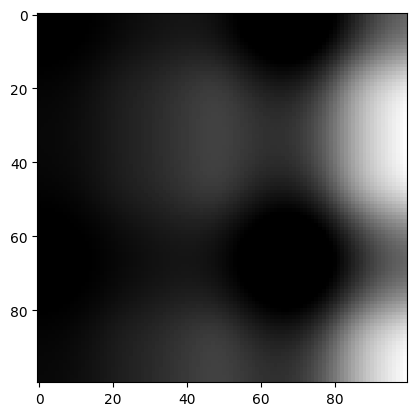

Light source direction: [0.57735027 0.57735027 0.57735027]


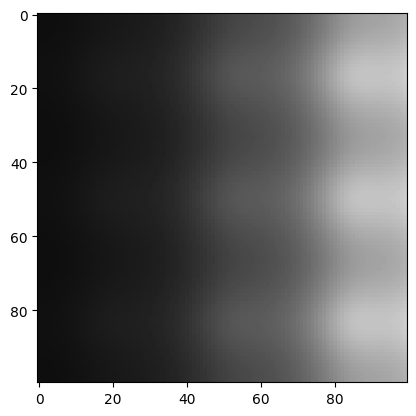

Light source direction: [0. 0. 1.]


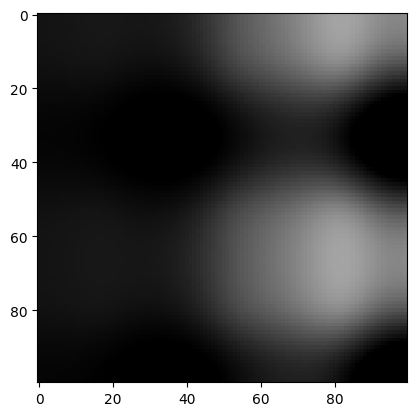

Light source direction: [-0.42426407 -0.70710678  0.56568542]


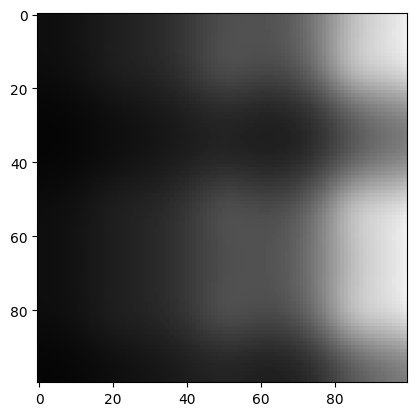

Light source direction: [ 0.21821789 -0.43643578  0.87287156]
Image shape: (100, 100)


In [2]:
## Example: How to read and access data from a pickle
pickle_in = open("data.pickle", "rb")
data = pickle.load(pickle_in, encoding="latin1")

# data is a dict which stores each element as a key-value pair. 
print("Keys: " + str(data.keys()))

# To access the value of an entity, refer it by its key.
print("Image:")
plt.imshow(data["im1"], cmap = "gray", vmin=0.0, vmax=1.0)
plt.show()

print("Light source direction: " + str(data["l1"]))

plt.imshow(data["im2"], cmap = "gray", vmin=0.0, vmax=1.0)
plt.show()

print("Light source direction: " + str(data["l2"]))

plt.imshow(data["im3"], cmap = "gray", vmin=0.0, vmax=1.0)
plt.show()

print("Light source direction: " + str(data["l3"]))

plt.imshow(data["im4"], cmap = "gray", vmin=0.0, vmax=1.0)
plt.show()

print("Light source direction: " + str(data["l4"]))
print(f"Image shape: {data['im1'].shape}")

### 1(a) Photometric Stereo [8 pts]
  
Implement the photometric stereo technique described in the lecture. Your program should have two parts:

- Read in the images and corresponding light source directions, and estimate the surface normals and albedo map.
- Reconstruct the depth map from the surface with the implementation of the Horn integration technique given below in `horn_integrate` function. Note that you will typically want to run the `horn_integrate` function with 10000 - 100000 iterations, meaning it will take a while.


**Note:**
- You MUST solve the system of equations as discussed in lecture
    - You may NOT use functions to solve it for you such as `np.linalg.pinv()`, `np.linalg.solve()`, `np.linalg.lstq()`.
- The following `horn_integrate()` function is not to be edited for the purpose of solving this homework. Consider this to be a blackbox! 

In [3]:
def horn_integrate(gx, gy, niter=25000):
    """
    horn_integrate recovers the function g from its partial 
    derivatives gx and gy. 
    mask is a binary image which tells which pixels are 
    involved in integration. 
    niter is the number of iterations. 
    typically 100,000 or 200,000, 
    although the trend can be seen even after 1000 iterations

    Parameters:
        gx: 2D array (H,W)
        gy: 2D array (H,W)
        mask: 2D array (H,W)
        niter: int

    Return: g: 2D array (H,W)
    """
    g = np.ones(np.shape(gx))
    mask = np.ones_like(g)
    
    gx = np.multiply(gx, mask)
    gy = np.multiply(gy, mask)
    
    A = np.array([[0,1,0],[0,0,0],[0,0,0]]) #y-1
    B = np.array([[0,0,0],[1,0,0],[0,0,0]]) #x-1
    C = np.array([[0,0,0],[0,0,1],[0,0,0]]) #x+1
    D = np.array([[0,0,0],[0,0,0],[0,1,0]]) #y+1
    
    d_mask = A + B + C + D
    
    den = np.multiply(convolve(mask,d_mask,mode="same"),mask)
    den[den == 0] = 1
    rden = 1.0 / den
    mask2 = np.multiply(rden, mask)
    
    m_a = convolve(mask, A, mode="same")
    m_b = convolve(mask, B, mode="same")
    m_c = convolve(mask, C, mode="same")
    m_d = convolve(mask, D, mode="same")
    
    term_right = np.multiply(m_c, gx) + np.multiply(m_d, gy)
    t_a = -1.0 * convolve(gx, B, mode="same")
    t_b = -1.0 * convolve(gy, A, mode="same")
    term_right = term_right + t_a + t_b
    term_right = np.multiply(mask2, term_right)
    
    for k in range(niter):
        g = np.multiply(mask2, convolve(g, d_mask, mode="same")) + term_right
    
    return g

In [4]:
def photometric_stereo(images, lights):
    """
    Implement the photometric stereo equations as described in lecture.

    Parameters:
        images: 3D array (n_imgs, h, w)
        lights: 2D array (n_imgs, 3)

    Return: tuple of (albedo, normals, H_horn)
        albedo: 2D array (h,w)
        normals: 3D array (h,w,3)
        H_horn: 2D array (h,w)
    """
    
    albedo = np.ones(images[0].shape)
    normals = np.dstack((np.zeros(images[0].shape),
                         np.zeros(images[0].shape),
                         np.ones(images[0].shape)))
    H_horn = np.ones(images[0].shape)

    """ YOUR CODE HERE """
    _, h, w = images.shape
    inv_lights = np.linalg.inv(lights.T @ lights) @ lights.T
    
    for i in range(int(h)):
        for j in range(int(w)):
            b = inv_lights @ images[:, i, j]
            albedo[i, j] = np.linalg.norm(b)
            normals[i, j, :] = b / albedo[i, j]
    
    nz = normals[:, :, 2]
    gx = normals[:, :, 0] / nz
    gy = normals[:, :, 1] / nz
    
    H_horn = horn_integrate(gx, gy, niter=10000)

    return albedo, normals, H_horn

### 1(b) Display outputs using `im1`, `im2` and `im4` [6 Points]

- The estimated albedo map.</li>

- The estimated surface normals by showing both
    - Needle map
    - Three images showing the components of the surface normal

- A wireframe of the depth map

An example of the outputs are shown below. Your results will not match these. We've provided code below to help you visualize them.

![Problem1%20example.png](Problem1%20example.png)

In [5]:
# from mpl_toolkits.mplot3d import Axes3D
def visualize(albedo, normals, horn_depth):
    """
    The following code is used to generate the albedo plot,
    the three normal component plots, and the wireframe
    depth map plot.

    Parameters:
        albedo: 2D array (h, w)
        normals: 3D array (h, w, 3)
        horn_depth: 2D array (h,w)
    """
    
    # Stride in the plot, you may want to adjust it to different images
    stride = 8

    # showing albedo map
    fig = plt.figure()
    albedo_max = albedo.max()
    albedo = albedo / albedo_max
    plt.imshow(albedo, cmap="gray", vmin=0.0, vmax=1.0)
    plt.show()

    # showing normals as three separate channels
    figure = plt.figure()
    ax1 = figure.add_subplot(131)
    ax1.imshow(normals[..., 0], vmin=0.0, vmax=1.0)
    ax2 = figure.add_subplot(132)
    ax2.imshow(normals[..., 1], vmin=0.0, vmax=1.0)
    ax3 = figure.add_subplot(133)
    ax3.imshow(normals[..., 2], vmin=0.0, vmax=1.0)
    plt.show()

    # showing normals as quiver
    X, Y, _ = np.meshgrid(np.arange(0,np.shape(normals)[0], stride),
                          np.arange(0,np.shape(normals)[1], stride),
                          np.arange(1))
    X = X[..., 0]
    Y = Y[..., 0]
    Z = horn_depth[::stride,::stride]
    NX = normals[..., 0][::stride,::stride]
    NY = normals[..., 1][::stride,::stride]
    NZ = normals[..., 2][::stride,::stride]
    fig = plt.figure(figsize=(5, 5))
    ax = fig.add_subplot(projection='3d')
    plt.quiver(X,Y,Z,NX,NY,NZ, length=2, antialiased=True)
    # set view to look parallel down the x axis, perpendicular to the y axis, at z=2.5
    # ax.view_init(elev=30, azim=340) # -> Can uncomment this if you want to adjust the perspective
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    plt.show()

    # plotting wireframe depth map

    H = horn_depth[::stride,::stride]
    fig = plt.figure()
    ax = fig.add_subplot(projection='3d')
    ax.plot_surface(X,Y,H)
    # ax.view_init(elev=30, azim=340)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    plt.show()

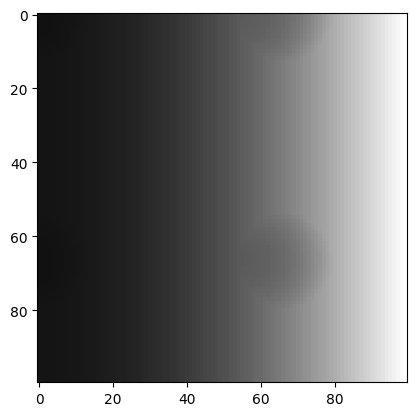

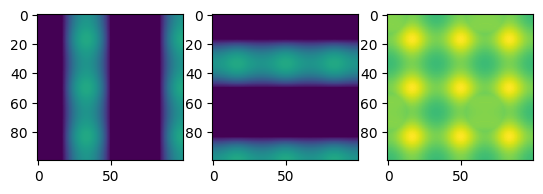

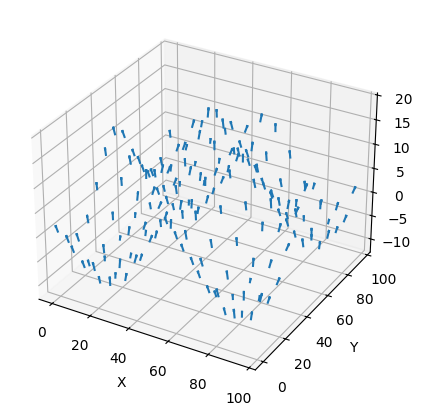

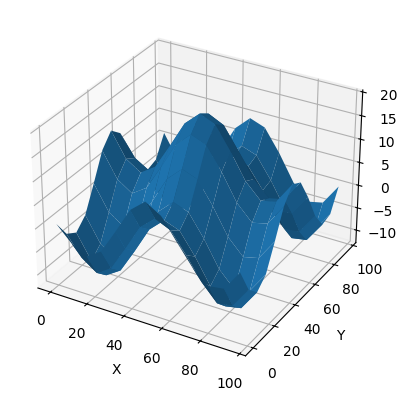

In [6]:
# Visualize the results using the three images-light source pairs: 
# (im1, l1), (im2, l2), and (im4, l4)
lights = np.vstack((data["l1"], data["l2"], data["l4"]))

images = []
images.append(data["im1"])
images.append(data["im2"])
images.append(data["im4"])
images = np.array(images)

albedo, normals, horn_depth = photometric_stereo(images, lights)

visualize(albedo, normals, horn_depth)

### 1(c) Display outputs using all four images (most accurate result) [6 points]
- The estimated albedo map.</li>

- The estimated surface normals by showing both
    - Needle map
    - Three images showing the components of the surface normal

- A wireframe of the depth map

You can refer to the code used in the cell above and adapt it to display the outputs for all the four images i.e im1, im2, im3 and im4 instead of just the 3 images i.e im1, im2 and im4 used before.

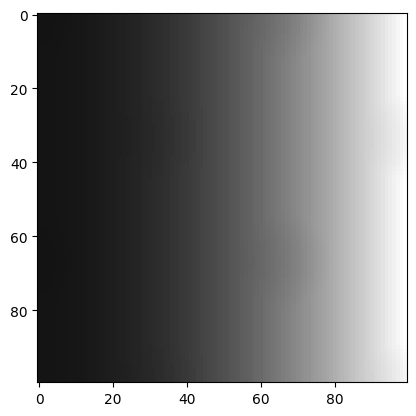

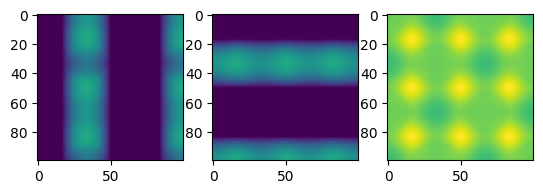

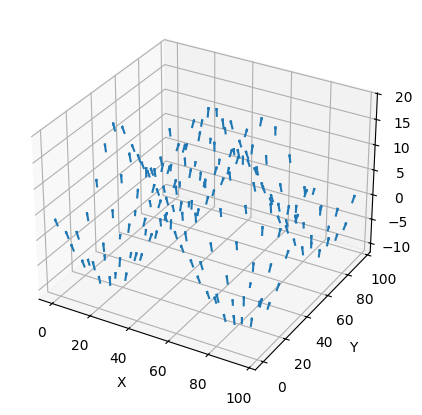

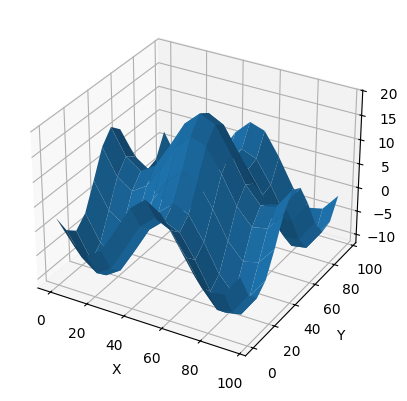

In [7]:
# Visualize the results using the four images-light source pairs: 
# (im1, l1), (im2, l2), (im3, l3) and (im4, l4)
""" YOUR CODE HERE """
lights = np.vstack([data[f"l{i}"] for i in range(1, 5)])
images = np.array([data[f"im{i}"] for i in range(1, 5)])

albedo, normals, horn_depth = photometric_stereo(images, lights)
visualize(albedo, normals, horn_depth)

## Problem 2: Image Rendering [20 points]


In this exercise, we will render the image of a face with two different point light sources using a Lambertian reflectance model. We will use two albedo maps, one uniform and one that is more realistic. The face heightmap, the light sources, and the two albedo are given in `facedata.npy` for Python (each row of the `lightsource` variable encode a light location). The data from `facedata.npy` is already provided to you.

**Note:** Please make good use out of subplot to display related image next to each other.

### 2(a) Plot the face in 2-D [2 pts]

Plot both albedo maps using `imshow`. Explain what you observe in brief.

In [8]:
# Load facedata.npy as ndarray
face_data = np.load('facedata.npy',encoding='latin1', allow_pickle=True)

# Load albedo matrix 
albedo = face_data.item().get('albedo')

# Load uniform albedo matrix
uniform_albedo = face_data.item().get('uniform_albedo')

# Load heightmap 
heightmap = face_data.item().get('heightmap')

# Load light source
light_source = face_data.item().get('light_source')


You should use the following link to learn about subplots: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html

Make sure to use `cmap=gray` while showing the images in grayscale format otherwise you can expect to see green-yellow colors. 

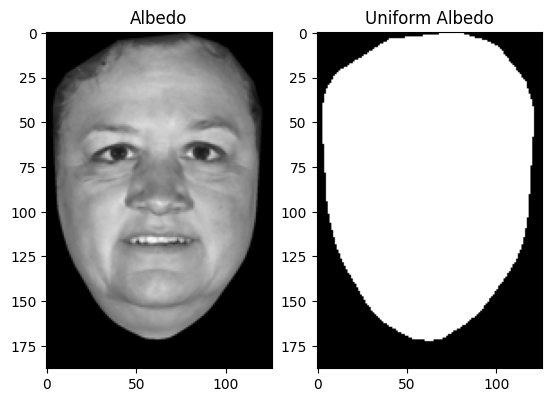

In [9]:
# Plot the face in 2-D (plot both albedo maps using imshow)
""" YOUR CODE HERE """
fig, axes = plt.subplots(1, 2)
axes[0].imshow(albedo, cmap="gray")
axes[0].set_title("Albedo")
axes[1].imshow(uniform_albedo, cmap="gray")
axes[1].set_title("Uniform Albedo")
plt.show()

### Explanation:

Using `albedo`, you see a face, while using `uniform_albedo`, you see the region the face covers, i.e. every pixel that the face occupies is colored white, otherwise black.

### 2(b) Plot the face in 3-D [2 pts]

Using both the heightmap and the albedo, plot the face using plot_surface. Do this for both albedos.
  
Learn about creating mesh grids here: https://numpy.org/doc/stable/reference/generated/numpy.mgrid.html'

Alternatively, use https://numpy.org/doc/stable/reference/generated/numpy.meshgrid.html

Learn about plotting surfaces here: https://matplotlib.org/2.2.5/api/_as_gen/mpl_toolkits.mplot3d.axes3d.Axes3D.html?highlight=plot_surface#mpl_toolkits.mplot3d.axes3d.Axes3D.plot_surface

This example may help you to put things together: https://matplotlib.org/2.0.2/examples/mplot3d/surface3d_demo.html


**Hint:** Make sure to set strides to one, cmap should be gray, linewidth is zero and antialiased is set to false. Figure out how to use albedo via the parameter `facecolors` -- you may want to look up `plt.cm.gray()`!

Currently, the height is stored along the **negative z-axis**. In the cell below, we've inverted it for visualization.

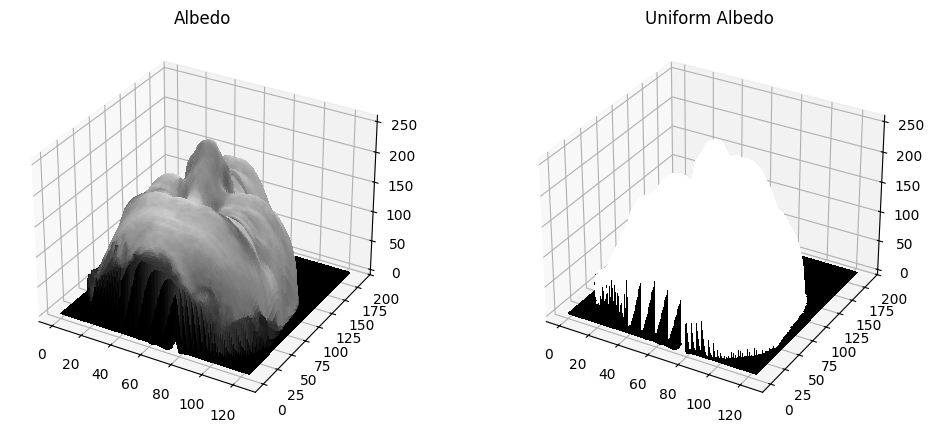

In [10]:
# Plot the face in 3-D 
# (Using the face_height & albedo plot the faces using plot_surface)
face_height = -heightmap # inverted heightmap for visualization

""" YOUR CODE HERE """
X, Y = np.meshgrid(np.arange(face_height.shape[1]), np.arange(face_height.shape[0]))
albedo_norm = albedo / albedo.max()
uniform_albedo_norm = uniform_albedo / uniform_albedo.max()

fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(X, Y, face_height,
                 facecolors=plt.cm.gray(albedo_norm),
                 cmap='gray',
                 rstride=1,
                 cstride=1,
                 linewidth=0,
                 antialiased=False)
ax1.set_title('Albedo')

ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, face_height,
                 facecolors=plt.cm.gray(uniform_albedo_norm),
                 cmap='gray',
                 rstride=1,
                 cstride=1,
                 linewidth=0,
                 antialiased=False)
ax2.set_title('Uniform Albedo')

plt.show()

### 2(c) Surface normals [8 pts]

Calculate the surface normals and display them as a quiver plot using quiver in `matplotlib` in Python. Recall that the surface normals are given by 

$$
[-\frac{\delta f}{\delta x}, -\frac{\delta f}{\delta y}, 1]
$$

Also, recall, that each normal vector should be normalized to unit length.

**Note:**
You can use differencing to compute spatial derivatives of discrete functions. You can use scipy's implementation on `convolve()` to achieve this. Learn about them here: https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.convolve.html

- You may NOT use `np.gradient()` or other functions to compute the partial derivatives for you
- You can convolve with the following kernels:
    - For partial derivatives in the x-direction, convolve with the kernel: $\begin{bmatrix} 0 & 0 & 0\\ 0.5 & 0 & -0.5\\ 0 & 0 & 0 \end{bmatrix}$
    - For partial derivatives in the y-direction, convolve with the kernel: $\begin{bmatrix} 0 & 0.5 & 0\\ 0 & 0 & 0\\ 0 & -0.5 & 0 \end{bmatrix}$
- You should use `mode=same` for this problem. (What does this do?)
- You do not need to invert the height map for this problem
    - The heightmap is initialized to create a right-handed coordinate system (positive x going right, positive y going downwards).

In [11]:
# Compute and plot the surface normals
# (make sure that the normal vector is normalized to unit length)

normals = np.stack((np.zeros(heightmap.shape),np.zeros(heightmap.shape),np.ones(heightmap.shape)), axis=-1)

# This part of the code should compute the normals i.e fill in the above normals variable correctly. Then just 
# execute the next cell to plot the surface normals

""" YOUR CODE HERE """
kernel_x = np.array([[0, 0, 0], [0.5, 0, -0.5], [0, 0, 0]])
kernel_y = np.array([[0, 0.5, 0], [0, 0, 0], [0, -0.5, 0]])

normals[:, :, 0] = -convolve(heightmap, kernel_x, mode='same')
normals[:, :, 1] = -convolve(heightmap, kernel_y, mode='same')

norm_magnitude = np.sqrt(normals[:, :, 0]**2 + normals[:, :, 1]**2 + normals[:, :, 2]**2)
normals = normals / norm_magnitude[:, :, np.newaxis]

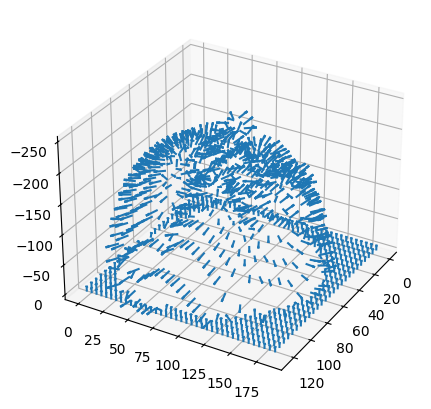

In [12]:
# This code is used to visualise the surface normals plot. 
# Feel free to change the stride variable below. However DO NOT change the other parts of this code. 

stride = 5
X, Y = np.meshgrid(np.arange(0, heightmap.shape[1], stride), np.arange(0,heightmap.shape[0],stride))
Z = heightmap[::stride,::stride]
NX = -normals[...,0][::stride,::stride] # Inverting to get outward normals
NY = -normals[...,1][::stride,::stride]
NZ = -normals[...,2][::stride,::stride]
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(projection = '3d')
xx, yy = np.mgrid[0:heightmap.shape[0], 0:heightmap.shape[1]]
ax.invert_zaxis()
ax.view_init(elev=30, azim=30)
plt.quiver(X,Y,Z, NX,NY,NZ, length=10)
plt.show()

### 2(d) Render images [8 pts]

For each of the two albedos, render three images. One for each of the two light sources, and one for both light-sources combined. Display these in a $2 \times 3$ subplot figure with titles. Recall that the general image formation equation is given by

I = a(x,y) \hat{\boldsymbol{\mathrm{n}}}(x,y)^\top \hat{\boldsymbol{\mathrm{s}}}(x,y) s_0

where $a(x,y)$ is the albedo for pixel $(x, y)$, $\hat{n}(x,y)$ is the corresponding surface normal, $\hat{s}(x,y)$ the light source direction, $s_0$ the light source intensity. Let the light source intensity be $1$ and make the 'distant light source assumption'.
Use `imshow` with appropriate keyword arguments.

**Note:** 
- Ensure that the images computed by `lambertian()` are within the range [0,1]. Otherwise, you will see gray image background (which should be black).
    - You can consider clipping the data using `np.clip()` to be within this range.

In [13]:
# Render Images
def lambertian(normals, light, albedo, intensity):
    """
    Given the normals, light source direction, albedo, and intensity,
    render an image according to the image formation model above.

    Parameters:
        normals: 3D array (h,w,3)
        light: 1D array (3,)
        albedo: 2D array (h,w)
        intensity: double

    Return: 2D array (h,w)
    """
    
    """ YOUR CODE HERE"""
    light = light / np.linalg.norm(light)
    image = albedo * np.sum(normals * light, axis=2) * intensity
    return np.clip(image, 0, 1)

When combining the two light sources, notice the linearity of the image formation equation. We can assume that light is additive meaning, to render an image with two light sources, we can render image 1 with light source 1 and image 2 with light source 2 independently, and then simply add images together element-wise (remember that this may cause the values outside of the range [0,1]).
$$
I_{final_img} = I_{im1} + I_{im2}
$$

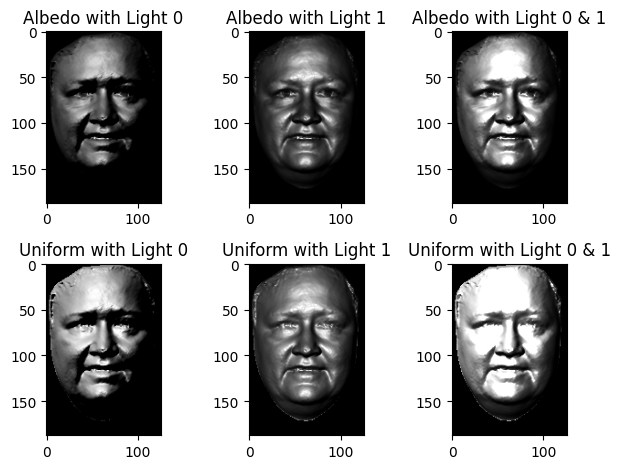

In [14]:
# For each of the two albedos, render three images. 
# One for each of the two light sources, and one for both light-sources combined.
""" YOUR CODE HERE """
fig, axes = plt.subplots(2, 3)
albedos = {"Albedo": albedo, "Uniform": uniform_albedo}

for i, (alb_type, alb) in enumerate(albedos.items()):
    img0 = lambertian(normals, light_source[0], alb, 1)
    axes[i, 0].imshow(img0, cmap="gray")
    axes[i, 0].set_title(f"{alb_type} with Light 0")
    
    img1 = lambertian(normals, light_source[1], alb, 1)
    axes[i, 1].imshow(img1, cmap="gray")
    axes[i, 1].set_title(f"{alb_type} with Light 1")
    
    axes[i, 2].imshow(np.clip(img0 + img1, 0, 1), cmap="gray")
    axes[i, 2].set_title(f"{alb_type} with Light 0 & 1")
    
plt.tight_layout()
plt.show()
plt.show()

## Problem 3: Camera Matrices and Rigid-Body Transformations [20 points]
  
Consider a world coordinate system $W$, centered at the origin $(0, 0, 0)$, with axes given by unit vectors $\widehat{\textbf{i}} = (1, 0, 0)^\top$, $\; \widehat{\textbf{j}} = (0,1,0)^\top$ and $\widehat{\textbf{k}} = (0,0,1)^\top$. We use a notation where boldfaces stand for a vector and a hat above a boldface letter stands for a unit vector.
  
<ul>
    <li><b>3(a)</b> Consider another coordinate system, with unit vectors along two of the orthogonal axes as:<br> $\widehat{\textbf{i}}' =  (0.688, −0.688, 0.229)^\top$ and $\widehat{\textbf{j}}' = (0.267, 0.534, 0.801)^\top$. Find the unit vector, $\widehat{\textbf{k}}'$, along the third axis orthogonal to both $\widehat{\textbf{i}}'$ and $\widehat{\textbf{j}}'$. Is there a unique such unit vector? If not, choose the one that makes an acute angle with $\widehat{\textbf{k}}$.<div style="text-align: right"><b>[2 Points]</b></div></li>
</ul>
    

In [15]:
np.set_printoptions(precision=3, suppress=True)

ip = np.array([0.688, -0.688, 0.229])
jp = np.array([0.267, 0.534, 0.801])

kp = np.cross(ip, jp)
kp = kp / np.linalg.norm(kp)

kp, np.linalg.norm(kp), bool(kp.T @ np.array([0, 0, 1]) > 0)

(array([-0.674, -0.491,  0.552]), np.float64(0.9999999999999999), True)

**Answer:** There are two vectors that are orthogonal to both $\widehat{\textbf{i}}'$ and $\widehat{\textbf{j}}'$. The one that makes an acute angle with $\widehat{\textbf{k}}$ is $\widehat{\textbf{k}}' = (-0.674, -0.491,  0.552)$. The other one is the negative of this.

<ul><li><b>3(b)</b> Find the rotation matrix that rotates any vector in the $(\widehat{\textbf{i}}, \widehat{\textbf{j}}, \widehat{\textbf{k}})$ coordinate system to the $(\widehat{\textbf{i}}', \widehat{\textbf{j}}', \widehat{\textbf{k}}')$ coordinate system.<div style="text-align: right"><b>[2 Points]</b></div></li></ul>
    
#### !! Hint !!

The rotation matrix is given by R =

$$
\begin{bmatrix}
    u^T \\
    v^T \\
    w^T \\
\end{bmatrix}
$$

**Answer:** $\begin{bmatrix}
    \widehat{\textbf{i}}'^T \\
    \widehat{\textbf{j}}'^T \\
    \widehat{\textbf{k}}'^T \\
\end{bmatrix} = \begin{bmatrix}
    0.688 & 0.267 & -0.673 \\
    -0.688 & 0.534 & -0.490 \\
    0.229 & 0.801 &  0.551 \\
\end{bmatrix}$

<ul><li><b>3(c)</b> What is the <em>extrinsic parameter matrix</em> for a camera at a displacement $(-1, -2, -5)^\top$ from the origin of $W$ and oriented such that its principal axis coincides with $\widehat{\textbf{k}}'$, the x-axis of its image plane coincides with $\widehat{\textbf{i}}'$ and the y-axis of the image plane coincides with $\widehat{\textbf{j}}'$? <div style="text-align: right"><b>[3 Points]</b></div></li></ul>

#### !! Hint !!
The extrinsic parameter matrix is given by: 

$$
\left(\begin{array}{cc} 
R & -RC\\
0^{T} & 1
\end{array}\right)
$$

where R is the rotation matrix and C is the camera center.
    

In [16]:
C = np.array([-1, -2, -5])
R = np.vstack([ip, jp, kp]).T
-R @ C

array([-2.15 , -2.073,  4.59 ])

**Answer:** $\begin{bmatrix} 
    0.688 & 0.267 & -0.674 & -2.150 \\
    -0.688 & 0.534 & -0.491 & -2.073 \\
    0.229 & 0.801 &  0.552 & 4.590 \\
    0 & 0 & 0 & 1
\end{bmatrix}$

<ul><li><b>3(d)</b> What is the <em>intrinsic parameter matrix</em> for this camera, if its focal length in the x-direction is $1024$ pixels, aspect ratio is $1$, pixels deviate from rectangular by $0$ degrees and principal point is offset from the center $(0, 0)^\top$ of the image plane to the location $(10, -5)^\top$?<div style="text-align: right"><b>[3 Points]</b></div></li></ul>
    

**Answer:** $K = \begin{bmatrix} 1024 & 0 & 10 \\ 0 & 1024 & -5 \\ 0 & 0 & 1 \end{bmatrix}$

<ul><li><b>3(e)</b> Write down the projection matrix for the camera described by the configuration in parts <b>3(c)</b> and <b>3(d)</b>. <div style="text-align: right"><b>[3 Points]</b></div></li></ul>

#### !! Hint !!

The projection matrix is given by P = K [ R | −RC ] where K in the intrinsic matrix, R is the rotation matrix and C is the camera center. 
    

In [17]:
K = np.array([[1024, 0, 10], [0, 1024, -5], [0, 0, 1]])
P = K @ np.hstack([R, (-R @ C).reshape(3, 1)])
P

array([[  706.802,   281.418,  -684.992, -2155.321],
       [ -705.657,   542.811,  -505.173, -2145.899],
       [    0.229,     0.801,     0.552,     4.59 ]])

**Answer:** $\begin{bmatrix} 
    706.802 & 281.418 & -684.992 & -2155.321 \\
    -705.657 & 542.811 & -505.173 & -2145.899 \\
    0.229 & 0.801 &  0.552 & 4.590 \\
\end{bmatrix}$

<ul><li><b>3(f)</b> Consider a plane, orthogonal to $\widehat{\textbf{k}}$, at a displacement of $1.5$ units from the origin of $W$ along the $\widehat{\textbf{k}}$ direction. Consider a star, centered at $(0, 0, 1.5)^\top$ in the coordinate system $W$. We wish to find the image of this star, as seen by the camera we constructed in part <b>3(e)</b>. The following questions need programming (use Python) and the code for each part should be turned in along with any figures and answers to specific questions. Explain your variable names (with comments). Feel free to supply any additional description or explanation to go with your code.
    
</li></ul>

<ul><ol>
<li> Compute 10000 well-distributed points on the surface of a star-shaped planar region. The boundary of the region is defined in polar coordinates by $r(\theta) = R_0 + A\cos(m\theta),$ with fixed parameters \(R_0 = 1\), \(A = 0.30\), and \(m = 5\) (Assume \(\theta\) is in radians). One way to do this is to sample the angular range $0$ to $360$ degrees into 10000 equal parts and convert the resulting points from polar coordinates to Cartesian coordinates. Display the resulting region, make sure that the axes of the display figure are equal.<div style="text-align: right"><b>[2 Points]</b></div></li>
</ol></ul>

### !! Hint !! 
The following code snippet generates one such random point: 
    
    theta = random() * 2 * PI
    r = sqrt(random()) * (R0 + A * cos(m * theta))

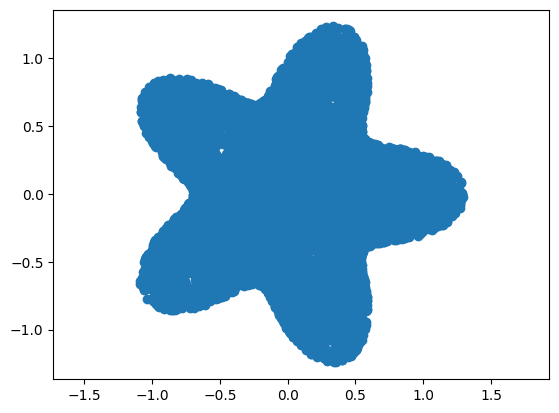

In [18]:
R0 = 1
A = 0.3
m = 5
n_points = 10_000
thetas = np.linspace(0, 2*np.pi, n_points)
rs = np.sqrt(np.random.rand(n_points)) * (R0 + A * np.cos(m * thetas))

xs = rs * np.cos(thetas)
ys = rs * np.sin(thetas)

plt.scatter(xs, ys)
plt.axis('equal')
plt.show()

<ul><ol start="2">
<li> Add the $z$ coordinate to these points, which is $2$ for all of them. Make all the points homogeneous by adding a fourth coordinate equal to $1$. <div style="text-align: right"><b>[1 Point]</b></div></li>
</ol></ul>        

In [19]:
zs = np.ones(n_points) * 2
ws = np.ones(n_points) # homogeneous coordinate

<ul><ol start="3">
<li> Compute the projection of these homogeneous points using the camera matrix from part <b>3(e)</b>. Convert the homogeneous projected points to 2D Cartesian points by dividing out (and subsequently discarding) the third coordinate of each point.<div style="text-align: right"><b>[2 Points]</b></div></li>
</ol></ul>        

In [20]:
coords = P @ np.vstack([xs, ys, zs, ws]) # scaled coords by z
coords /= coords[2]

<ul><ol start="4">
<li> Plot the projected 2D points, again ensure that the axes of your plot are equal. What is the shape of the image of a star? <div style="text-align: right"><b>[2 Points]</b></div></li>
</ol></ul>

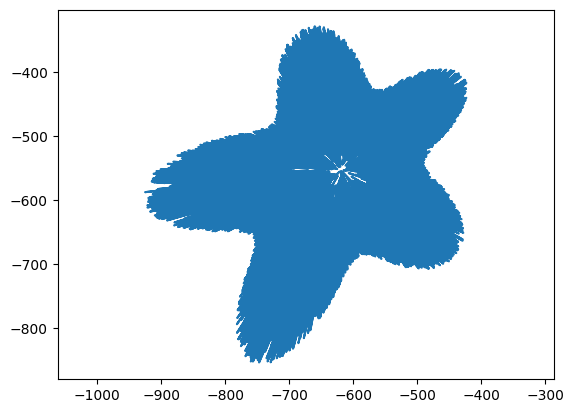

In [21]:
plt.plot(coords[0], coords[1]) # screen space coordinates
plt.axis('equal')
plt.show()

The star is stretched out like we're closer to the left side than the right. Interestingly, there's a lack of points near the center and the edges seem much rougher.

## Problem 4: Google Form [20 points]

Please complete the **[Google Form](https://docs.google.com/forms/d/e/1FAIpQLSdl3wMquXFKpKEgBrgSUFt4IcWN9vnK0DQE0N8QxJB3IsQMBw/viewform?usp=publish-editor)** and fill in the following required information:
  <ul>
    <li>Your full name as it appears on Gradescope</li>
    <li>Your PID</li>
    <li>Your GithHub email address</li>
    <li>Your GitHub username</li>
  </ul>
  
  Submit the form and confirm that you see a message indicating that your response has been recorded.
</li>